# Stage 2 — Exploratory Data Analysis

> This notebook preserves the original Google Advanced Data Analytics course progression. For the polished, leakage-safe workflow, see [the portfolio analysis](../tiktok_claims_portfolio.ipynb).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("../../data/tiktok_dataset.csv")

In [3]:
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [4]:
data.size

232584

In [5]:
data.shape

(19382, 12)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [7]:
data.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


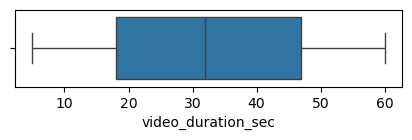

In [8]:
# Create a boxplot to visualize distribution of `video_duration_sec`
plt.figure(figsize=(5,1))
sns.boxplot(x=data["video_duration_sec"])
plt.show()

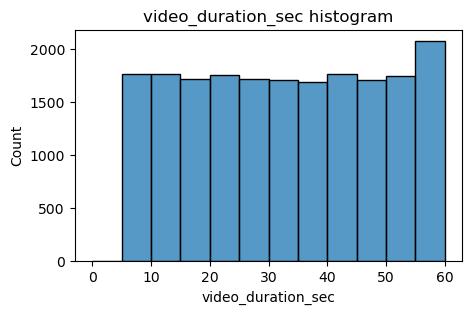

In [9]:
# Create a histogram
plt.figure(figsize=(5,3))
sns.histplot(data["video_duration_sec"], bins=range(0,61,5))
plt.title("video_duration_sec histogram")
plt.show()

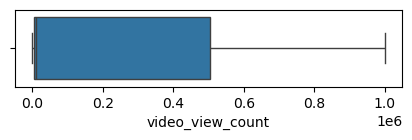

In [10]:
# Create a boxplot to visualize distribution of `video_view_count`
plt.figure(figsize=(5,1))
sns.boxplot(x=data["video_view_count"])
plt.show()

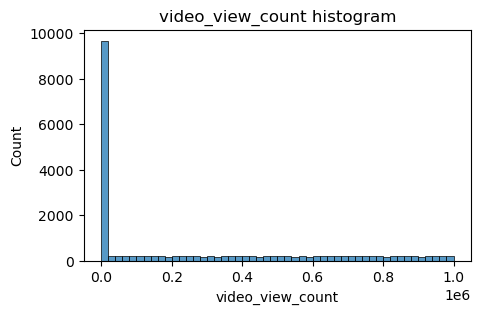

In [11]:
# Create a histogram
plt.figure(figsize=(5,3))
sns.histplot(data["video_view_count"], bins=range(0,(10**6+1),20000))
plt.title("video_view_count histogram")
plt.show()

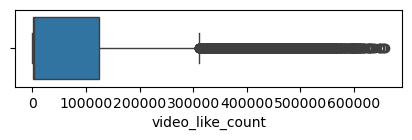

In [12]:
# Create a boxplot to visualize distribution of `video_like_count`
plt.figure(figsize=(5,1))
sns.boxplot(x=data["video_like_count"])
plt.show()

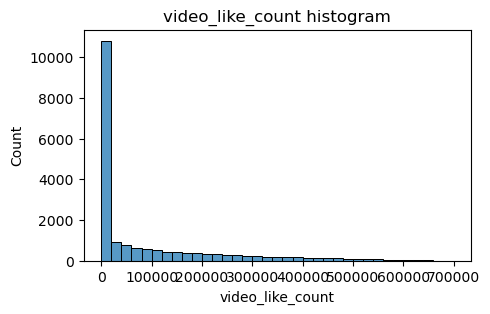

In [13]:
# Create a histogram
plt.figure(figsize=(5,3))
sns.histplot(data["video_like_count"], bins=range(0,(700000+1),20000))
plt.title("video_like_count histogram")
plt.show()

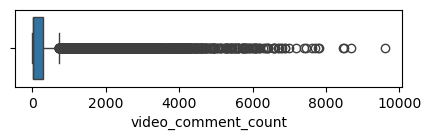

In [14]:
# Create a boxplot to visualize distribution of `video_comment_count`
plt.figure(figsize=(5,1))
sns.boxplot(x=data["video_comment_count"])
plt.show()

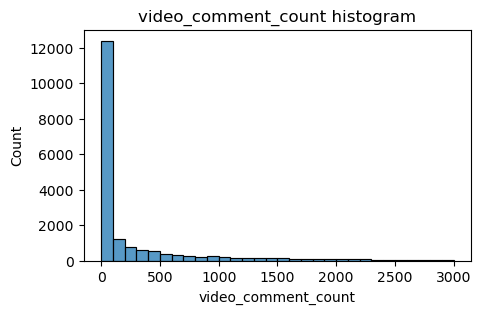

In [15]:
# Create a histogram
plt.figure(figsize=(5,3))
sns.histplot(data["video_comment_count"], bins=range(0,(3000+1),100))
plt.title("video_comment_count histogram")
plt.show()

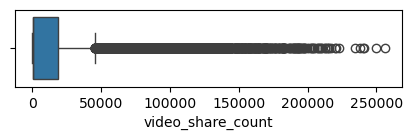

In [16]:
# Create a boxplot to visualize distribution of `video_share_count`
plt.figure(figsize=(5,1))
sns.boxplot(x=data["video_share_count"])
plt.show()

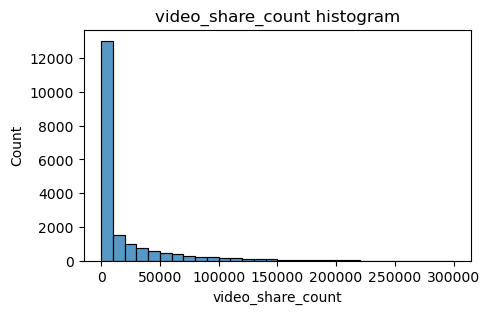

In [17]:
# Create a histogram
plt.figure(figsize=(5,3))
sns.histplot(data["video_share_count"], bins=range(0,(300000+1),10000))
plt.title("video_share_count histogram")
plt.show()

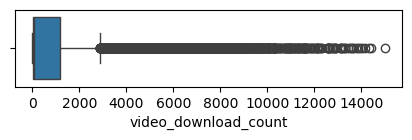

In [18]:
# Create a boxplot to visualize distribution of `video_download_count`
plt.figure(figsize=(5,1))
sns.boxplot(x=data["video_download_count"])
plt.show()

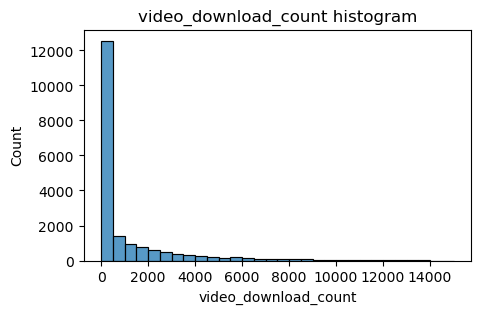

In [19]:
# Create a histogram
plt.figure(figsize=(5,3))
sns.histplot(data["video_download_count"], bins=range(0,(15000+1),500))
plt.title("video_download_count histogram")
plt.show()

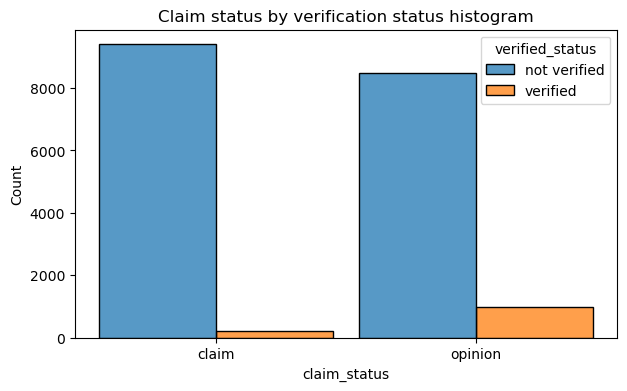

In [20]:
# Create a histogram
plt.figure(figsize=(7,4))
sns.histplot(data=data,
             x="claim_status",
             hue="verified_status",
             multiple="dodge",
             shrink=0.9)
plt.title("Claim status by verification status histogram")
plt.show()

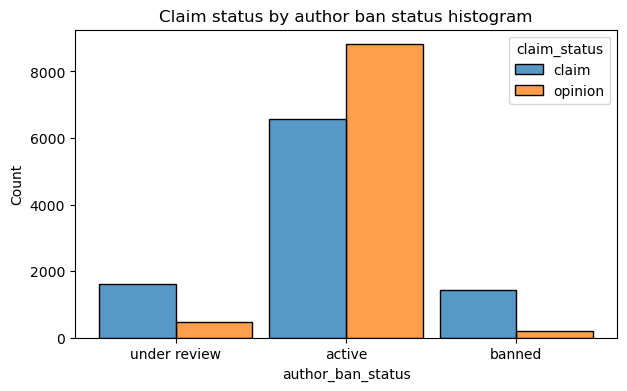

In [21]:
# Create a histogram
plt.figure(figsize=(7,4))
sns.histplot(data=data,
             x="author_ban_status",
             hue="claim_status",
             multiple="dodge",
             shrink=0.9)
plt.title("Claim status by author ban status histogram")
plt.show()

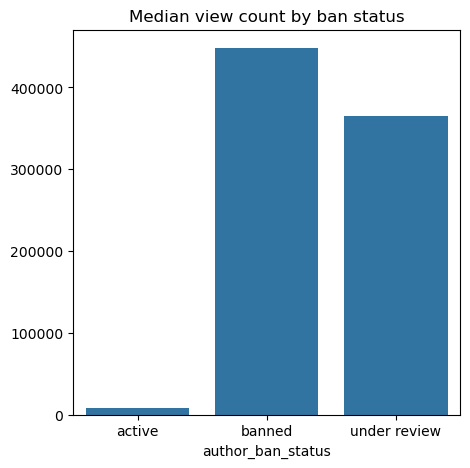

In [22]:
# Create a bar plot
ban_status_counts = data.groupby("author_ban_status")["video_view_count"].median()

plt.figure(figsize=(5,5))
sns.barplot(x=ban_status_counts.index, y=ban_status_counts.values)
plt.title("Median view count by ban status")
plt.show()

In [23]:
# Calculate the median view count for claim status.
data.groupby("claim_status")["video_view_count"].median()

claim_status
claim      501555.0
opinion      4953.0
Name: video_view_count, dtype: float64

In [24]:
# This cell is likely a continuation — e.g. printing/formatting the result,
# or it could be left for the learner's own exploration/notes.
# A common follow-up is to double check with describe():
data.groupby("claim_status")["video_view_count"].describe()

,count,mean,std,min,25%,50%,75%,max
claim_status,,,,,,,,
claim,9608.0,501029.452748,291349.239825,1049.0,247003.75,501555.0,753088.00,999817.0
opinion,9476.0,4956.432250,2885.907219,20.0,2467.00,4953.0,7447.25,9998.0


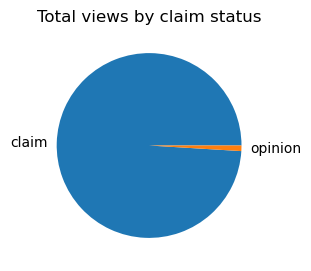

In [25]:
# Create a pie graph
fig = plt.figure(figsize=(3,3))
plt.pie(data.groupby("claim_status")["video_view_count"].sum(),
        labels=["claim", "opinion"])
plt.title("Total views by claim status")
plt.show()

In [26]:
# Define the columns to check for outliers
count_cols = ["video_view_count", "video_like_count", "video_share_count",
              "video_download_count", "video_comment_count"]

for column in count_cols:
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    median = data[column].median()
    outlier_threshold = median + 1.5 * iqr

    # Count the number of values that exceed the outlier threshold
    outlier_count = (data[column] > outlier_threshold).sum()

    print(f"Number of outliers, {column}: {outlier_count}")

Number of outliers, video_view_count: 2343
Number of outliers, video_like_count: 3468
Number of outliers, video_share_count: 3732
Number of outliers, video_download_count: 3733
Number of outliers, video_comment_count: 3882


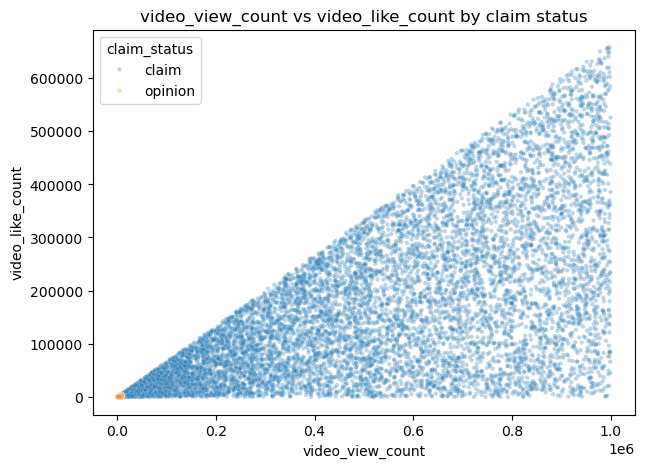

In [27]:
# Create a scatterplot of `video_view_count` versus `video_like_count` according to 'claim_status'
plt.figure(figsize=(7,5))
sns.scatterplot(x=data["video_view_count"], y=data["video_like_count"],
                 hue=data["claim_status"], s=10, alpha=0.3)
plt.title("video_view_count vs video_like_count by claim status")
plt.show()

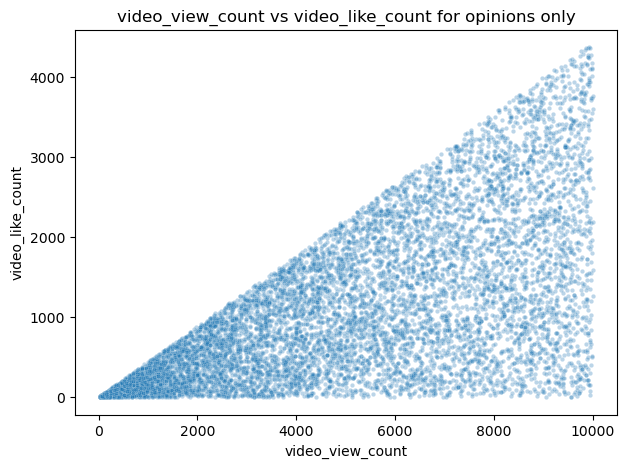

In [28]:
# Create a scatterplot of `video_view_count` versus `video_like_count` for opinions only
opinion = data[data["claim_status"]=="opinion"]

plt.figure(figsize=(7,5))
sns.scatterplot(x=opinion["video_view_count"], y=opinion["video_like_count"],
                 s=10, alpha=0.3)
plt.title("video_view_count vs video_like_count for opinions only")
plt.show()